<h2>3. Build and fine-tune a classification model using just embeddings</h2>
a. Build a basic multilayer perceptron (MLP) to perform classification based on the
concatenated features at the previous step. Fine-tune it on the supervised training set for N
epochs, like what you did in Section 2.

b. Plot the learning curves on training and validation set. After how many epochs should we
stop the training?

Here is the thing performed in this section

3 Hidden layer model

&nbsp;&nbsp;&nbsp;&nbsp;1. Train with a grid of parameters to decide which parameters to use

&nbsp;&nbsp;&nbsp;&nbsp;2. Train a model using the best parameters from before (more epochs)

&nbsp;&nbsp;&nbsp;&nbsp;3. Plot recall, accuracy, precision, f1, ROC, AUC, confusion matrix on validation set

&nbsp;&nbsp;&nbsp;&nbsp;4. Plot recall, accuracy, precision, f1, ROC, AUC, confusion matrix on test set

2 Hidden layer model

&nbsp;&nbsp;&nbsp;&nbsp;1. Train with a grid of parameters to decide which parameters to use

&nbsp;&nbsp;&nbsp;&nbsp;2. Train a model using the best parameters from before (more epochs)

&nbsp;&nbsp;&nbsp;&nbsp;3. Plot recall, accuracy, precision, f1, ROC, AUC, confusion matrix on validation set

&nbsp;&nbsp;&nbsp;&nbsp;4. Plot recall, accuracy, precision, f1, ROC, AUC, confusion matrix on test set

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
from sklearn.model_selection import train_test_split
import seaborn as sns
from sklearn.preprocessing import StandardScaler
import numpy as np
from sklearn.metrics import precision_recall_fscore_support, roc_curve, auc, precision_recall_curve, average_precision_score

import torch
from torch import nn
import torch.nn.functional as F
import itertools

In [2]:
X_combined = pd.read_csv('X_combined.csv', index_col=0).iloc[:, -768:]
target_df=pd.read_csv('target_supervised.csv')
target_df = target_df.set_index('author').loc[X_combined.index].reset_index()

X_train, X_test, y_train, y_test = train_test_split(X_combined, target_df['gender'], stratify=target_df['gender'], train_size=0.85, random_state=15)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, stratify=y_train, train_size=0.7/0.85, random_state=15)

print(X_train.shape, X_val.shape, X_test.shape)

scaler = StandardScaler()
scaler.fit(X_train)
X_train_s, X_val_s, X_test_s = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)

X_train = torch.tensor(X_train_s, dtype=torch.float)
y_train = torch.tensor(y_train.values, dtype=torch.long)
X_val = torch.tensor(X_val_s, dtype=torch.float)
y_val = torch.tensor(y_val.values, dtype=torch.long)
X_test = torch.tensor(X_test_s, dtype=torch.float)
y_test = torch.tensor(y_test.values, dtype=torch.long)

(3500, 768) (750, 768) (750, 768)


In [3]:
def accuracy_fn(y_true, y_pred):
    correct = torch.eq(y_true, y_pred).sum().item()
    acc = (correct / len(y_pred))
    return acc

def confusion_matrix(y_true, y_pred):
    df = pd.DataFrame([x for x in zip([x.item() for x in y_true], [x.item() for x in y_pred])], columns=['y_true', 'y_pred'])
    df[['samples']] = 1
    confusion = pd.pivot_table(df, index='y_true', columns='y_pred', values='samples', aggfunc="sum")
    plt.figure()
    sns.heatmap(confusion, cmap='Blues', annot=True, cbar_kws={'label':'Occurrences'}, fmt='g')
    plt.xlabel('Prediction')
    plt.ylabel('True')    
    plt.title('Confusion matrix')
    plt.show()

<h3>Trying a model with 3 hidden layers</h3>

In [4]:
# Define the neural network
class Model_classification(nn.Module): 
    def __init__(
        self, 
        in_features, # number of input features
        out_features, # number of output features
        hidden_1, # number of neurons in the 1st hidden layer
        hidden_2, # number of neurons in the 2nd hidden layer
        hidden_3 # number of neurons in the 3rd hidden layer
    ):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=in_features, out_features=hidden_1) # 1st linear layer
        self.layer_2 = nn.Linear(in_features=hidden_1, out_features=hidden_2) # 2nd linear layer
        self.layer_3 = nn.Linear(in_features=hidden_2, out_features=hidden_3) # 3rd linear layer

        self.layer_output = nn.Linear(in_features=hidden_3, out_features=out_features) # output layer
        self.activation_1 = nn.Tanh() # activation function
        #self.activation_2 = nn.Softmax(dim=1) # activation function

    # define feedforward process
    def forward(self, x):
        #x = x.flatten(start_dim=1) #to go from 28x28 image tensor to 784 input tensor
        out = self.activation_1(self.layer_1(x)) #output of 1st hidden layer
        out = self.activation_1(self.layer_2(out)) #output of 2nd hidden layer
        out = self.activation_1(self.layer_3(out))
        #out = self.activation_2(self.layer_output(out)) #output of the nn
        out = self.layer_output(out) 
        
        return out

In [5]:
torch.manual_seed(8)
dim_features = X_combined.shape[1]#This is the size of input features
loss_fn = nn.CrossEntropyLoss()

In [6]:
def create_batches(data, labels, batch_size):
    num_samples = data.shape[0]
    batches = []
    for i in range(0, num_samples, batch_size):
        data_batch = data[i:i + batch_size]
        label_batch = labels[i:i + batch_size]
        batches.append((data_batch, label_batch))
    return batches

<h4>Train models to find the best parameters</h4>

In [7]:
# Define parameter grid
param_grid = {
    'learning_rate': [1e-5],
    'hidden_1': [1000,  2000, 4000],
    'hidden_2': [1500, 750, 2500],
    'hidden_3': [250, 500, 1000],
    'batch_size': [32, 64]
}

# Generate all combinations
keys, values = zip(*param_grid.items())
param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_val_acc = 0
best_params = None

for params in param_combinations:
    # Create model with current parameters
    model = Model_classification(
        in_features=dim_features,
        out_features=2,
        hidden_1=params['hidden_1'],
        hidden_2=params['hidden_2'],
        hidden_3=params['hidden_3']
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=params['learning_rate'])
    batch_size = params['batch_size']
    batches = create_batches(X_train, y_train, batch_size)

    epoch = 0
    current_max_acc = 0
    stop = False
    max_cumulated_epochs = 5
    current_cumulated_epochs = 0
    
    while not stop:
        # model training phase
        model.train()
        for _, (data_batch, label_batch) in enumerate(batches):
            y_prob = model(data_batch).squeeze() # get the output probability of predictions
            loss_batch = loss_fn(y_prob, label_batch) # calculate the loss
            optimizer.zero_grad() # reset the gradients of model parameters
            loss_batch.backward() # backpropagate the prediction loss
            optimizer.step() # adjust the parameters by the gradients 

        # model evaluation phase
        model.eval()
        
        # training set
        y_prob = model(X_train).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) # get the label
        acc_train = accuracy_fn(y_true=y_train, y_pred=y_pred)

        # validation set
        y_prob = model(X_val).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) 
        acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)

        if current_max_acc -  acc_val < 0: 
            current_max_acc =  acc_val
        else:
            current_cumulated_epochs += 1
            if current_cumulated_epochs >= max_cumulated_epochs:
                stop = True

        if acc_train==1.0:
            stop=True

    print(f"Params: {params}, Val Acc: {acc_val:.4f}")
    if acc_val > best_val_acc:
        best_val_acc = acc_val
        best_params = params

print("Best parameters:", best_params, "accuracy value:", best_val_acc)

Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 250, 'batch_size': 32}, Val Acc: 0.7587
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7640
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 500, 'batch_size': 32}, Val Acc: 0.7733
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 500, 'batch_size': 64}, Val Acc: 0.7640
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 32}, Val Acc: 0.7667
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 64}, Val Acc: 0.7547
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 32}, Val Acc: 0.7627
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7600
Params: {'learning_rate': 1e-05,

In [8]:
# To analyze results without executing the whole grid search again
best_params = {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 32}

<h4> Train the model with the best parameters found in best_params</h4>


In [9]:
# Train the model with the best parameters found in best_params
model = Model_classification(
    in_features=dim_features,
    out_features=2,
    hidden_1=best_params['hidden_1'],
    hidden_2=best_params['hidden_2'],
    hidden_3=best_params['hidden_3']
)
optimizer = torch.optim.Adam(model.parameters(), lr=best_params['learning_rate'])

batch_size = best_params['batch_size']
batches = create_batches(X_train, y_train, batch_size)

epoch=0
loss_train_all = []
loss_val_all = []
acc_train_all = []
acc_val_all = []
current_max_acc = 0
current_cumulated_epochs = 0
max_cumulated_epochs = 10
stop = False

while not stop:
    # Training phase
    model.train()
    loss_all = []
    for data_batch, label_batch in batches:
        y_prob = model(data_batch)
        loss = loss_fn(y_prob, label_batch)
        loss_all.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    # Evaluation phase
    model.eval()
    with torch.no_grad():
        # Training set
        y_prob_train = model(X_train)
        y_pred_train = torch.argmax(y_prob_train, dim=1)
        acc_train = accuracy_fn(y_train, y_pred_train)
        
        # Validation set
        y_prob_val = model(X_val)
        loss_val = loss_fn(y_prob_val, y_val)
        y_pred_val = torch.argmax(y_prob_val, dim=1)
        acc_val = accuracy_fn(y_val, y_pred_val)
    
    # Collect results
    loss_train_all.append(np.mean(loss_all))
    loss_val_all.append(loss_val.item())
    acc_train_all.append(acc_train)
    acc_val_all.append(acc_val)
    
    print(f'Epoch: {epoch+1} | Train Loss: {loss_train_all[-1]:.5f}, Val Loss: {loss_val_all[-1]:.5f}, Train Acc: {acc_train:.4f}, Val Acc: {acc_val:.4f}')
    epoch += 1

    # if the evaluated accuracy is not larger than the maximum accuracy recorded, we increase the cumulation of epochs of 1
    if current_max_acc -  acc_val < 0: 
        current_max_acc =  acc_val
        #save model state
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        current_cumulated_epochs += 1
        if current_cumulated_epochs >= max_cumulated_epochs:
            stop = True

# Load the best model
model.load_state_dict(torch.load('best_model.pth'))

Epoch: 1 | Train Loss: 0.60696, Val Loss: 0.55548, Train Acc: 0.7494, Val Acc: 0.7133
Epoch: 2 | Train Loss: 0.52368, Val Loss: 0.51317, Train Acc: 0.7837, Val Acc: 0.7387
Epoch: 3 | Train Loss: 0.47956, Val Loss: 0.48707, Train Acc: 0.8009, Val Acc: 0.7560
Epoch: 4 | Train Loss: 0.44860, Val Loss: 0.47274, Train Acc: 0.8166, Val Acc: 0.7680
Epoch: 5 | Train Loss: 0.42745, Val Loss: 0.46746, Train Acc: 0.8229, Val Acc: 0.7827
Epoch: 6 | Train Loss: 0.41306, Val Loss: 0.46772, Train Acc: 0.8263, Val Acc: 0.7800
Epoch: 7 | Train Loss: 0.40267, Val Loss: 0.47069, Train Acc: 0.8283, Val Acc: 0.7827
Epoch: 8 | Train Loss: 0.39444, Val Loss: 0.47480, Train Acc: 0.8314, Val Acc: 0.7813
Epoch: 9 | Train Loss: 0.38735, Val Loss: 0.47930, Train Acc: 0.8346, Val Acc: 0.7800
Epoch: 10 | Train Loss: 0.38090, Val Loss: 0.48391, Train Acc: 0.8371, Val Acc: 0.7747
Epoch: 11 | Train Loss: 0.37481, Val Loss: 0.48854, Train Acc: 0.8411, Val Acc: 0.7760
Epoch: 12 | Train Loss: 0.36894, Val Loss: 0.49316, 

<All keys matched successfully>

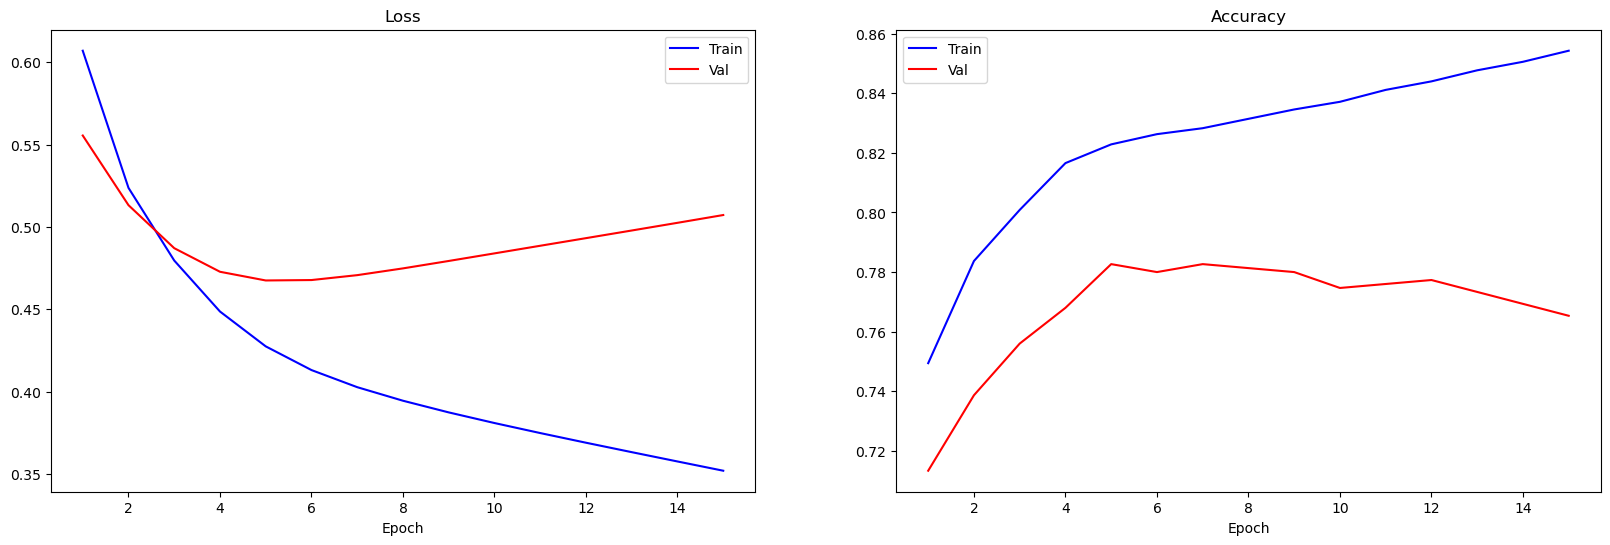

In [10]:
# visualize the evolution of losses and accuracies
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(20,6))

ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.plot(range(1, len(loss_train_all) + 1), loss_train_all, label='Train', color='blue')
ax1.plot(range(1, len(loss_val_all) + 1), loss_val_all, label='Val', color='red')
ax1.legend()

ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.plot(range(1, len(acc_train_all) + 1), acc_train_all, label='Train', color='blue')
ax2.plot(range(1, len(acc_val_all) + 1), acc_val_all, label='Val', color='red')
ax2.legend()

plt.show()

The accuracy is: 0.7826666666666666


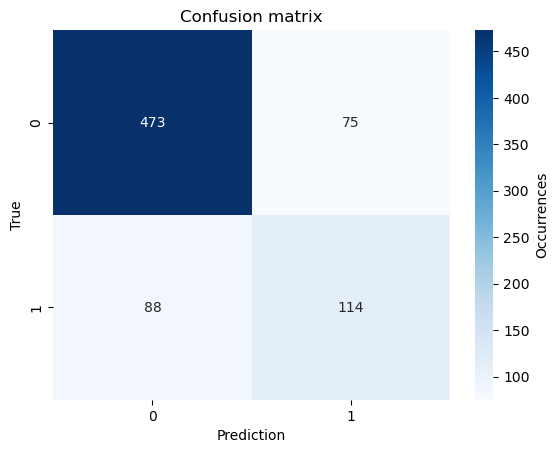

In [11]:
# visualize (final) confusion matrix on validation set
y_prob = model(X_val).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)
print('The accuracy is:', acc_val)
confusion_matrix(y_val, y_pred)

Precision: 0.7785
Recall:    0.7827
F1-score:  0.7803
Class 0 - Precision: 0.8431, Recall: 0.8631, F1-score: 0.8530
Class 1 - Precision: 0.6032, Recall: 0.5644, F1-score: 0.5831


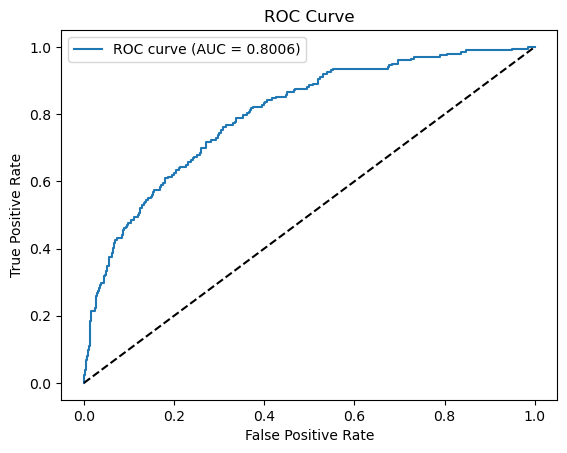

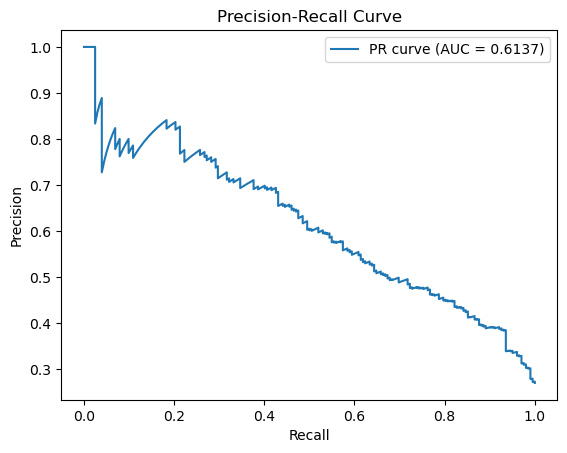

In [12]:
# Convert torch tensors to numpy arrays
y_val_np = y_val.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_val_np, y_pred_np, average='weighted')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_val_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_val_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_val_np, y_prob_np)
pr_auc = average_precision_score(y_val_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

The accuracy is: 0.7773333333333333


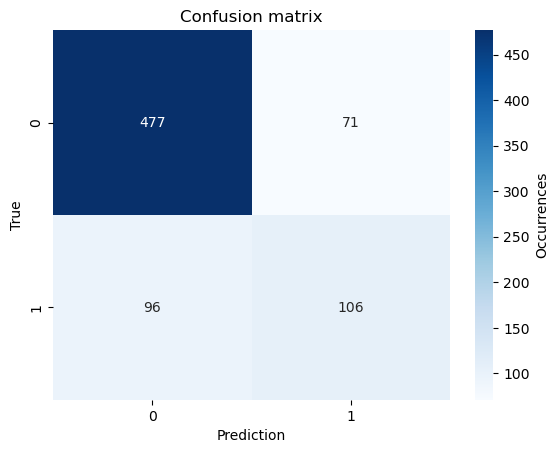

In [13]:
# visualize (final) confusion matrix on test set
y_prob = model(X_test).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_test = accuracy_fn(y_true=y_test, y_pred=y_pred)
print('The accuracy is:', acc_test)
confusion_matrix(y_test, y_pred)

Precision: 0.7695
Recall:    0.7773
F1-score:  0.7725
Class 0 - Precision: 0.8325, Recall: 0.8704, F1-score: 0.8510
Class 1 - Precision: 0.5989, Recall: 0.5248, F1-score: 0.5594


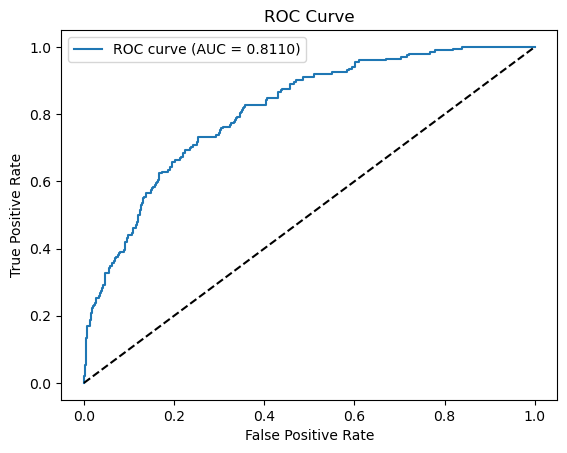

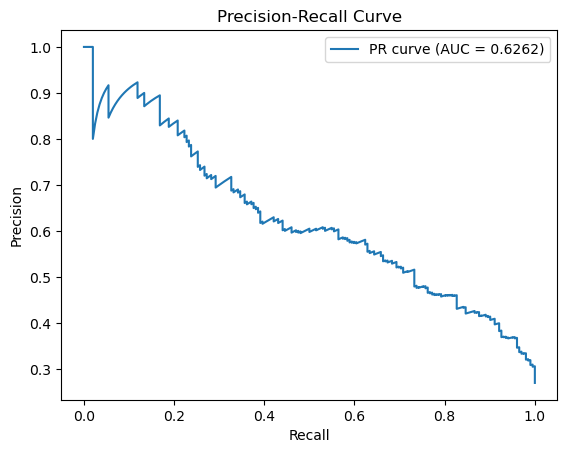

In [14]:
# Convert torch tensors to numpy arrays
y_test_np = y_test.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average='weighted')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_test_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test_np, y_prob_np)
pr_auc = average_precision_score(y_test_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

<h3>Trying with a 2 layer model</h3>

In [15]:
# Define the neural network
class Model_classification(nn.Module): 
    def __init__(
        self, 
        in_features, # number of input features
        out_features, # number of output features
        hidden_1, # number of neurons in the 1st hidden layer
        hidden_2, # number of neurons in the 2nd hidden layer
    ):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=in_features, out_features=hidden_1) # 1st linear layer
        self.layer_2 = nn.Linear(in_features=hidden_1, out_features=hidden_2) # 2nd linear layer

        self.layer_output = nn.Linear(in_features=hidden_2, out_features=out_features) # output layer
        self.activation_1 = nn.Tanh() # activation function
        #self.activation_2 = nn.Softmax(dim=1) # activation function

    # define feedforward process
    def forward(self, x):
        #x = x.flatten(start_dim=1) #to go from 28x28 image tensor to 784 input tensor
        out = self.activation_1(self.layer_1(x)) #output of 1st hidden layer
        out = self.activation_1(self.layer_2(out)) #output of 2nd hidden layer
        #out = self.activation_1(self.layer_3(out))
        #out = self.activation_2(self.layer_output(out)) #output of the nn
        out = self.layer_output(out) 
        
        return out

In [16]:
# Define parameter grid
param_grid = {
    'learning_rate': [1e-5],
    'hidden_1': [7500, 5000, 2500],
    'hidden_2': [5000, 2500, 1250],
    'batch_size': [32, 64]
}

# Generate all combinations
keys, values = zip(*param_grid.items())
param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_val_acc = 0
best_params = None

for params in param_combinations:
    # Create model with current parameters
    model = Model_classification(
        in_features=dim_features,
        out_features=2,
        hidden_1=params['hidden_1'],
        hidden_2=params['hidden_2'],
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=params['learning_rate'])
    batch_size = params['batch_size']
    batches = create_batches(X_train, y_train, batch_size)

    epoch = 0
    current_max_acc = 0
    stop = False
    max_cumulated_epochs = 5
    current_cumulated_epochs = 0
    
    while not stop:
        # model training phase
        model.train()
        for _, (data_batch, label_batch) in enumerate(batches):
            y_prob = model(data_batch).squeeze() # get the output probability of predictions
            loss_batch = loss_fn(y_prob, label_batch) # calculate the loss
            optimizer.zero_grad() # reset the gradients of model parameters
            loss_batch.backward() # backpropagate the prediction loss
            optimizer.step() # adjust the parameters by the gradients 

        # model evaluation phase
        model.eval()
        
        # training set
        y_prob = model(X_train).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) # get the label
        acc_train = accuracy_fn(y_true=y_train, y_pred=y_pred)

        # validation set
        y_prob = model(X_val).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) 
        acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)

        if current_max_acc -  acc_val < 0: 
            current_max_acc =  acc_val
        else:
            current_cumulated_epochs += 1
            if current_cumulated_epochs >= max_cumulated_epochs:
                stop = True

        if acc_train==1.0:
            stop=True
    print(f"Params: {params}, Val Acc: {acc_val:.4f}")
    if acc_val > best_val_acc:
        best_val_acc = acc_val
        best_params = params

print("Best parameters:", best_params)

Params: {'learning_rate': 1e-05, 'hidden_1': 7500, 'hidden_2': 5000, 'batch_size': 32}, Val Acc: 0.7613
Params: {'learning_rate': 1e-05, 'hidden_1': 7500, 'hidden_2': 5000, 'batch_size': 64}, Val Acc: 0.7613
Params: {'learning_rate': 1e-05, 'hidden_1': 7500, 'hidden_2': 2500, 'batch_size': 32}, Val Acc: 0.7640
Params: {'learning_rate': 1e-05, 'hidden_1': 7500, 'hidden_2': 2500, 'batch_size': 64}, Val Acc: 0.7653
Params: {'learning_rate': 1e-05, 'hidden_1': 7500, 'hidden_2': 1250, 'batch_size': 32}, Val Acc: 0.7693
Params: {'learning_rate': 1e-05, 'hidden_1': 7500, 'hidden_2': 1250, 'batch_size': 64}, Val Acc: 0.7667
Params: {'learning_rate': 1e-05, 'hidden_1': 5000, 'hidden_2': 5000, 'batch_size': 32}, Val Acc: 0.7680
Params: {'learning_rate': 1e-05, 'hidden_1': 5000, 'hidden_2': 5000, 'batch_size': 64}, Val Acc: 0.7547
Params: {'learning_rate': 1e-05, 'hidden_1': 5000, 'hidden_2': 2500, 'batch_size': 32}, Val Acc: 0.7627
Params: {'learning_rate': 1e-05, 'hidden_1': 5000, 'hidden_2': 2

In [17]:
#To analyze results without executing the whole grid search again
best_params = {'learning_rate': 1e-05, 'hidden_1': 2500, 'hidden_2': 2500, 'batch_size': 32}

In [18]:
# Train the model with the best parameters found in best_params
model = Model_classification(
    in_features=dim_features,
    out_features=2,
    hidden_1=best_params['hidden_1'],
    hidden_2=best_params['hidden_2'],
)
optimizer = torch.optim.Adam(model.parameters(), lr=best_params['learning_rate'])

batch_size = best_params['batch_size']
batches = create_batches(X_train, y_train, batch_size)

epoch=0
loss_train_all = []
loss_val_all = []
acc_train_all = []
acc_val_all = []
current_max_acc = 0
current_cumulated_epochs = 0
max_cumulated_epochs = 10
stop = False

while not stop:
    # Training phase
    model.train()
    loss_all = []
    for data_batch, label_batch in batches:
        y_prob = model(data_batch)
        loss = loss_fn(y_prob, label_batch)
        loss_all.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    # Evaluation phase
    model.eval()
    with torch.no_grad():
        # Training set
        y_prob_train = model(X_train)
        y_pred_train = torch.argmax(y_prob_train, dim=1)
        acc_train = accuracy_fn(y_train, y_pred_train)
        
        # Validation set
        y_prob_val = model(X_val)
        loss_val = loss_fn(y_prob_val, y_val)
        y_pred_val = torch.argmax(y_prob_val, dim=1)
        acc_val = accuracy_fn(y_val, y_pred_val)
    
    # Collect results
    loss_train_all.append(np.mean(loss_all))
    loss_val_all.append(loss_val.item())
    acc_train_all.append(acc_train)
    acc_val_all.append(acc_val)
    
    print(f'Epoch: {epoch+1} | Train Loss: {loss_train_all[-1]:.5f}, Val Loss: {loss_val_all[-1]:.5f}, Train Acc: {acc_train:.4f}, Val Acc: {acc_val:.4f}')
    epoch += 1

    # if the evaluated accuracy is not larger than the maximum accuracy recorded, we increase the cumulation of epochs of 1
    if current_max_acc -  acc_val < 0: 
        current_max_acc =  acc_val
        #save model state
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        current_cumulated_epochs += 1
        if current_cumulated_epochs >= max_cumulated_epochs:
            stop = True

# Load the best model
model.load_state_dict(torch.load('best_model.pth'))

Epoch: 1 | Train Loss: 0.60018, Val Loss: 0.56416, Train Acc: 0.7369, Val Acc: 0.7120
Epoch: 2 | Train Loss: 0.53162, Val Loss: 0.53191, Train Acc: 0.7703, Val Acc: 0.7293
Epoch: 3 | Train Loss: 0.49346, Val Loss: 0.50934, Train Acc: 0.7949, Val Acc: 0.7413
Epoch: 4 | Train Loss: 0.46396, Val Loss: 0.49413, Train Acc: 0.8086, Val Acc: 0.7587
Epoch: 5 | Train Loss: 0.44090, Val Loss: 0.48489, Train Acc: 0.8171, Val Acc: 0.7613
Epoch: 6 | Train Loss: 0.42296, Val Loss: 0.48022, Train Acc: 0.8251, Val Acc: 0.7587
Epoch: 7 | Train Loss: 0.40890, Val Loss: 0.47875, Train Acc: 0.8309, Val Acc: 0.7600
Epoch: 8 | Train Loss: 0.39762, Val Loss: 0.47939, Train Acc: 0.8323, Val Acc: 0.7640
Epoch: 9 | Train Loss: 0.38826, Val Loss: 0.48131, Train Acc: 0.8346, Val Acc: 0.7640
Epoch: 10 | Train Loss: 0.38018, Val Loss: 0.48399, Train Acc: 0.8391, Val Acc: 0.7653
Epoch: 11 | Train Loss: 0.37295, Val Loss: 0.48708, Train Acc: 0.8420, Val Acc: 0.7667
Epoch: 12 | Train Loss: 0.36628, Val Loss: 0.49040, 

<All keys matched successfully>

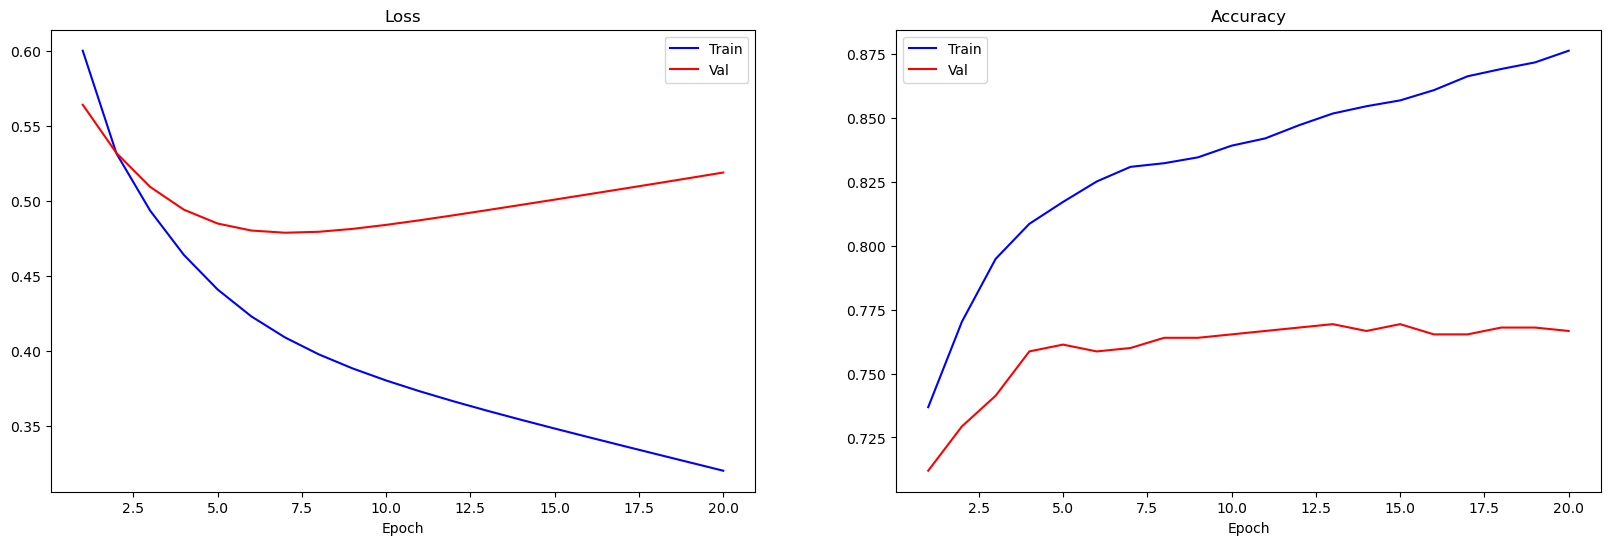

The accuracy is: 0.7693333333333333


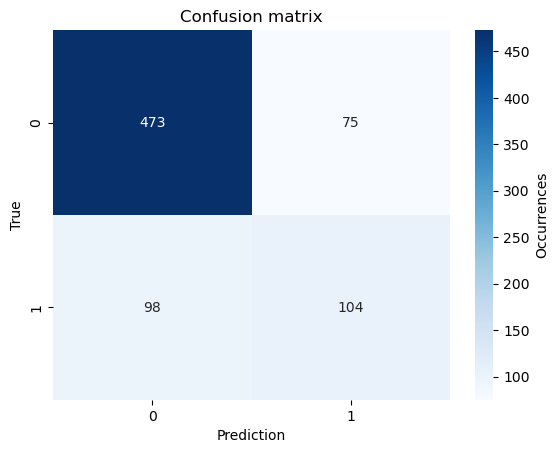

In [19]:
# visualize the evolution of losses and accuracies
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(20,6))

ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.plot(range(1, len(loss_train_all) + 1), loss_train_all, label='Train', color='blue')
ax1.plot(range(1, len(loss_val_all) + 1), loss_val_all, label='Val', color='red')
ax1.legend()

ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.plot(range(1, len(acc_train_all) + 1), acc_train_all, label='Train', color='blue')
ax2.plot(range(1, len(acc_val_all) + 1), acc_val_all, label='Val', color='red')
ax2.legend()

plt.show()

# visualize confusion matrix on validation set
y_prob = model(X_val).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)
print('The accuracy is:', acc_val)
confusion_matrix(y_val, y_pred)

Compute precision, recall F1 score for the validation set. And plot ROC & AUC

Precision: 0.7617
Recall:    0.7693
F1-score:  0.7647
Class 0 - Precision: 0.8284, Recall: 0.8631, F1-score: 0.8454
Class 1 - Precision: 0.5810, Recall: 0.5149, F1-score: 0.5459


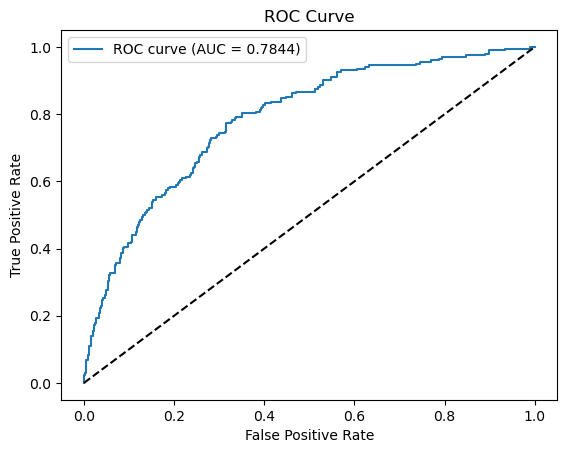

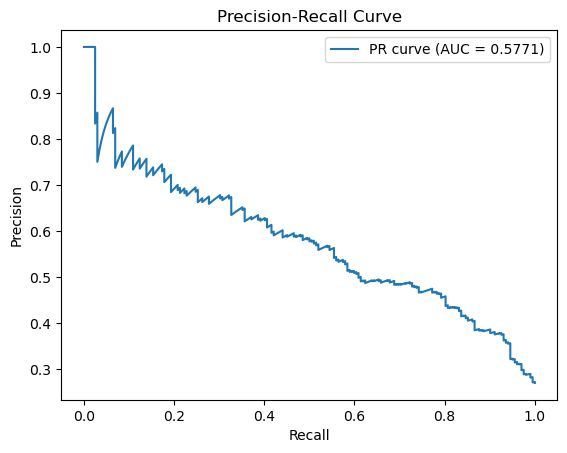

In [20]:
# Convert torch tensors to numpy arrays
y_val_np = y_val.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_val_np, y_pred_np, average='weighted')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_val_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_val_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_val_np, y_prob_np)
pr_auc = average_precision_score(y_val_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

The accuracy is: 0.7573333333333333


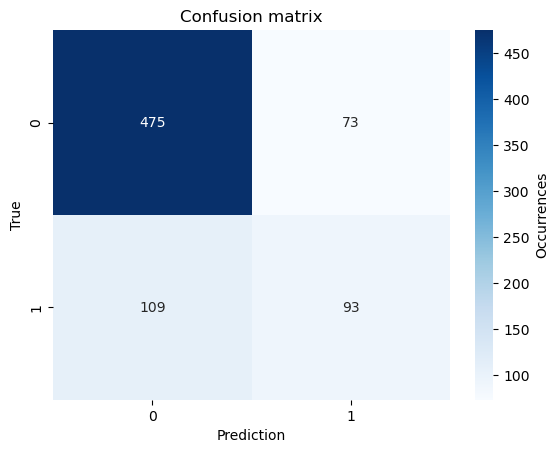

In [21]:
# visualize (final) confusion matrix on test set
y_prob = model(X_test).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_test = accuracy_fn(y_true=y_test, y_pred=y_pred)
print('The accuracy is:', acc_test)
confusion_matrix(y_test, y_pred)

Compute precision, recall F1 score for the validation set. And plot ROC & AUC

Precision: 0.7452
Recall:    0.7573
F1-score:  0.7493
Class 0 - Precision: 0.8134, Recall: 0.8668, F1-score: 0.8392
Class 1 - Precision: 0.5602, Recall: 0.4604, F1-score: 0.5054


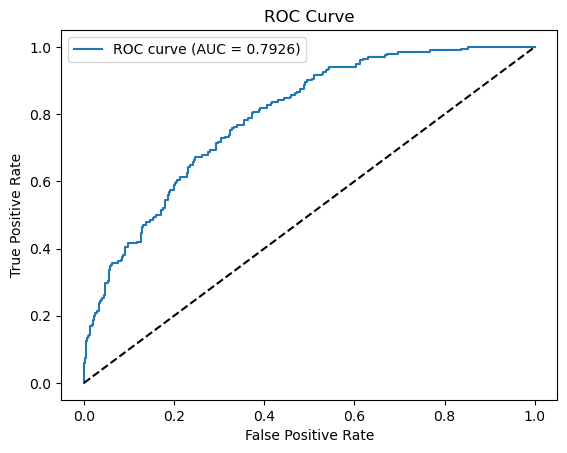

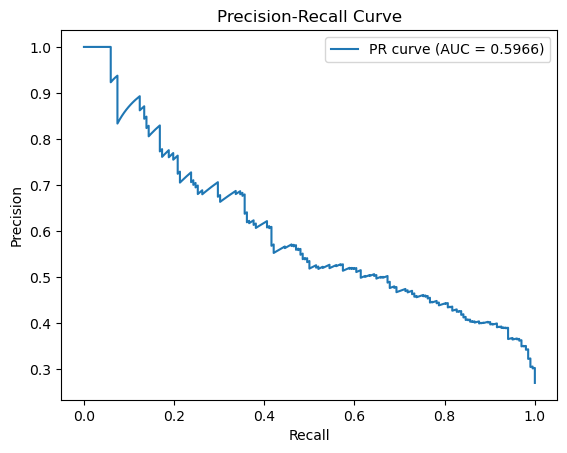

In [22]:
# Convert torch tensors to numpy arrays
y_test_np = y_test.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average='weighted')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_test_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test_np, y_prob_np)
pr_auc = average_precision_score(y_test_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

<h3>Trying a 3 layer with leaky-ReLu</h3>

In [23]:
# Define the neural network
class Model_classification(nn.Module): 
    def __init__(
        self, 
        in_features, # number of input features
        out_features, # number of output features
        hidden_1, # number of neurons in the 1st hidden layer
        hidden_2, # number of neurons in the 2nd hidden layer
        hidden_3 # number of neurons in the 3rd hidden layer
    ):
        super().__init__()
        self.layer_1 = nn.Linear(in_features=in_features, out_features=hidden_1) # 1st linear layer
        self.layer_2 = nn.Linear(in_features=hidden_1, out_features=hidden_2) # 2nd linear layer
        self.layer_3 = nn.Linear(in_features=hidden_2, out_features=hidden_3) # 3rd linear layer
        self.layer_output = nn.Linear(in_features=hidden_3, out_features=out_features) # output layer
        
        #self.activation_1 = nn.Tanh() # activation function
        #self.activation_2 = nn.Softmax(dim=1) # activation function
        self.activation_3 = nn.LeakyReLU() # activation function

    # define feedforward process
    def forward(self, x):
        #x = x.flatten(start_dim=1) #to go from 28x28 image tensor to 784 input tensor
        out = self.activation_3(self.layer_1(x)) #output of 1st hidden layer
        out = self.activation_3(self.layer_2(out)) #output of 2nd hidden layer
        out = self.activation_3(self.layer_3(out))
        #out = self.activation_2(self.layer_output(out)) #output of the nn
        out = self.layer_output(out) 
        
        return out

In [24]:
# Define parameter grid
param_grid = {
    'learning_rate': [1e-5],
    'hidden_1': [1000,  2000, 4000],
    'hidden_2': [1500, 750, 2500],
    'hidden_3': [250, 500, 1000],
    'batch_size': [32, 64]
}

# Generate all combinations
keys, values = zip(*param_grid.items())
param_combinations = [dict(zip(keys, v)) for v in itertools.product(*values)]

best_val_acc = 0
best_params = None

for params in param_combinations:
    # Create model with current parameters
    model = Model_classification(
        in_features=dim_features,
        out_features=2,
        hidden_1=params['hidden_1'],
        hidden_2=params['hidden_2'],
        hidden_3=params['hidden_3']
    )
    optimizer = torch.optim.Adam(model.parameters(), lr=params['learning_rate'])
    batch_size = params['batch_size']
    batches = create_batches(X_train, y_train, batch_size)

    epoch = 0
    current_max_acc = 0
    stop = False
    max_cumulated_epochs = 5
    current_cumulated_epochs = 0
    
    while not stop:
        # model training phase
        model.train()
        for _, (data_batch, label_batch) in enumerate(batches):
            y_prob = model(data_batch).squeeze() # get the output probability of predictions
            loss_batch = loss_fn(y_prob, label_batch) # calculate the loss
            optimizer.zero_grad() # reset the gradients of model parameters
            loss_batch.backward() # backpropagate the prediction loss
            optimizer.step() # adjust the parameters by the gradients 

        # model evaluation phase
        model.eval()
        
        # training set
        y_prob = model(X_train).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) # get the label
        acc_train = accuracy_fn(y_true=y_train, y_pred=y_pred)

        # validation set
        y_prob = model(X_val).squeeze()
        y_pred = torch.argmax(y_prob, dim=-1) 
        acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)

        if current_max_acc -  acc_val < 0: 
            current_max_acc =  acc_val
        else:
            current_cumulated_epochs += 1
            if current_cumulated_epochs >= max_cumulated_epochs:
                stop = True

        if acc_train==1.0:
            stop=True
    print(f"Params: {params}, Val Acc: {acc_val:.4f}")
    if acc_val > best_val_acc:
        best_val_acc = acc_val
        best_params = params

print("Best parameters:", best_params)

Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 250, 'batch_size': 32}, Val Acc: 0.7720
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7853
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 500, 'batch_size': 32}, Val Acc: 0.7640
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 500, 'batch_size': 64}, Val Acc: 0.7747
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 32}, Val Acc: 0.7760
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 1500, 'hidden_3': 1000, 'batch_size': 64}, Val Acc: 0.7747
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 32}, Val Acc: 0.7787
Params: {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 64}, Val Acc: 0.7813
Params: {'learning_rate': 1e-05,

In [25]:
# To analyze results without executing the whole grid search again
# best_params = {'learning_rate': 1e-05, 'hidden_1': 1000, 'hidden_2': 750, 'hidden_3': 250, 'batch_size': 64}

In [26]:
# Train the model with the best parameters found in best_params
model = Model_classification(
    in_features=dim_features,
    out_features=2,
    hidden_1=best_params['hidden_1'],
    hidden_2=best_params['hidden_2'],
    hidden_3=best_params['hidden_3']
)
optimizer = torch.optim.Adam(model.parameters(), lr=best_params['learning_rate'])

batch_size = best_params['batch_size']
batches = create_batches(X_train, y_train, batch_size)

epoch=0
loss_train_all = []
loss_val_all = []
acc_train_all = []
acc_val_all = []
current_max_acc = 0
current_cumulated_epochs = 0
max_cumulated_epochs = 10
stop = False

while not stop:
    # Training phase
    model.train()
    loss_all = []
    for data_batch, label_batch in batches:
        y_prob = model(data_batch)
        loss = loss_fn(y_prob, label_batch)
        loss_all.append(loss.item())
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
    
    # Evaluation phase
    model.eval()
    with torch.no_grad():
        # Training set
        y_prob_train = model(X_train)
        y_pred_train = torch.argmax(y_prob_train, dim=1)
        acc_train = accuracy_fn(y_train, y_pred_train)
        
        # Validation set
        y_prob_val = model(X_val)
        loss_val = loss_fn(y_prob_val, y_val)
        y_pred_val = torch.argmax(y_prob_val, dim=1)
        acc_val = accuracy_fn(y_val, y_pred_val)
    
    # Collect results
    loss_train_all.append(np.mean(loss_all))
    loss_val_all.append(loss_val.item())
    acc_train_all.append(acc_train)
    acc_val_all.append(acc_val)
    
    print(f'Epoch: {epoch+1} | Train Loss: {loss_train_all[-1]:.5f}, Val Loss: {loss_val_all[-1]:.5f}, Train Acc: {acc_train:.4f}, Val Acc: {acc_val:.4f}')
    epoch += 1

    # if the evaluated accuracy is not larger than the maximum accuracy recorded, we increase the cumulation of epochs of 1
    if current_max_acc -  acc_val < 0: 
        current_max_acc =  acc_val
        #save model state
        torch.save(model.state_dict(), 'best_model.pth')
    else:
        current_cumulated_epochs += 1
        if current_cumulated_epochs >= max_cumulated_epochs:
            stop = True

# Load the best model
model.load_state_dict(torch.load('best_model.pth'))

Epoch: 1 | Train Loss: 0.63683, Val Loss: 0.58347, Train Acc: 0.7300, Val Acc: 0.7307
Epoch: 2 | Train Loss: 0.55460, Val Loss: 0.53984, Train Acc: 0.7300, Val Acc: 0.7307
Epoch: 3 | Train Loss: 0.51838, Val Loss: 0.51151, Train Acc: 0.7314, Val Acc: 0.7320
Epoch: 4 | Train Loss: 0.48879, Val Loss: 0.48877, Train Acc: 0.7623, Val Acc: 0.7640
Epoch: 5 | Train Loss: 0.46526, Val Loss: 0.47368, Train Acc: 0.7877, Val Acc: 0.7840
Epoch: 6 | Train Loss: 0.44766, Val Loss: 0.46537, Train Acc: 0.8003, Val Acc: 0.7787
Epoch: 7 | Train Loss: 0.43421, Val Loss: 0.46156, Train Acc: 0.8060, Val Acc: 0.7787
Epoch: 8 | Train Loss: 0.42324, Val Loss: 0.46017, Train Acc: 0.8163, Val Acc: 0.7800
Epoch: 9 | Train Loss: 0.41342, Val Loss: 0.45999, Train Acc: 0.8189, Val Acc: 0.7813
Epoch: 10 | Train Loss: 0.40406, Val Loss: 0.46048, Train Acc: 0.8240, Val Acc: 0.7773
Epoch: 11 | Train Loss: 0.39477, Val Loss: 0.46146, Train Acc: 0.8283, Val Acc: 0.7707
Epoch: 12 | Train Loss: 0.38528, Val Loss: 0.46287, 

<All keys matched successfully>

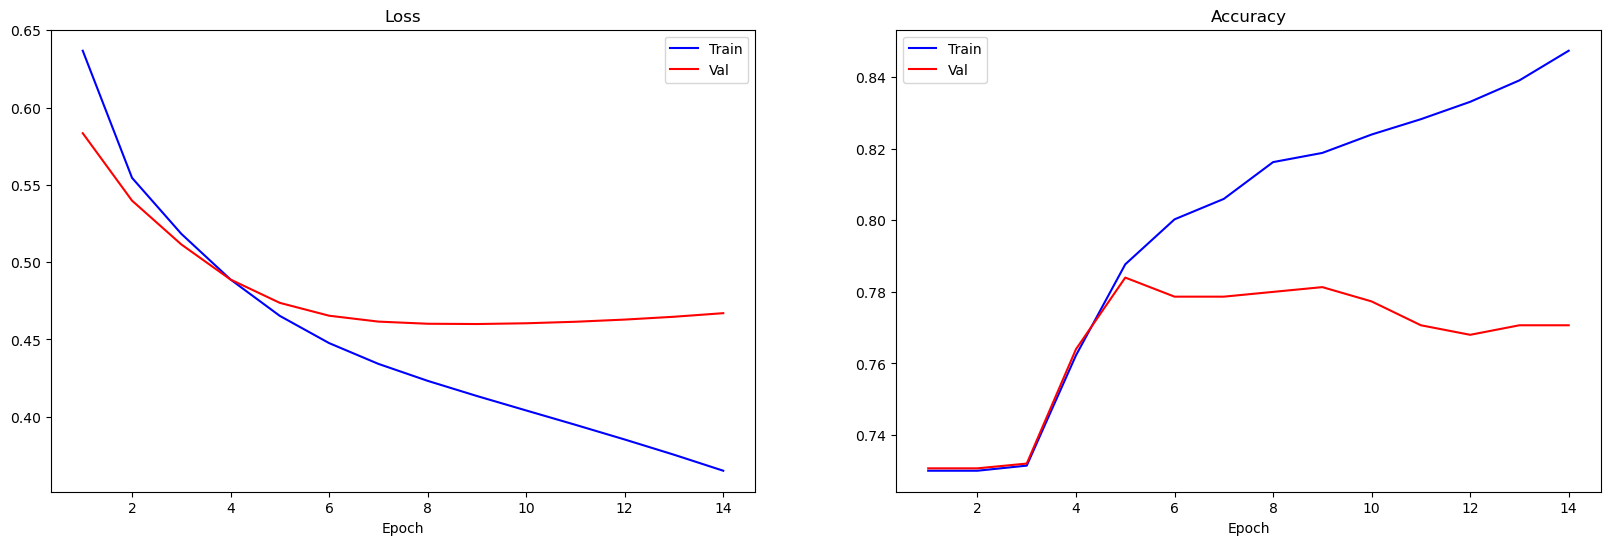

The accuracy is: 0.784


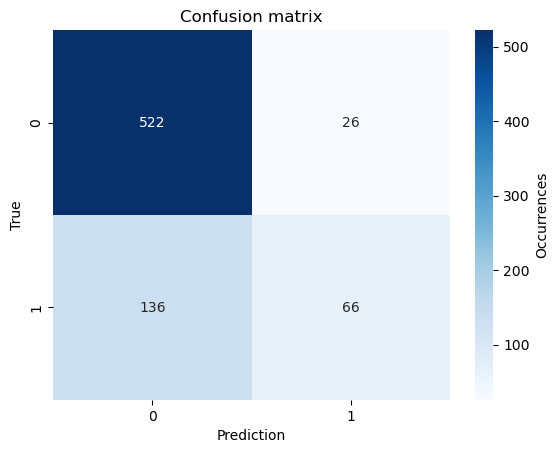

In [27]:
# visualize the evolution of losses and accuracies
fig, (ax1, ax2) = plt.subplots(1,2, figsize=(20,6))

ax1.set_title('Loss')
ax1.set_xlabel('Epoch')
ax1.plot(range(1, len(loss_train_all) + 1), loss_train_all, label='Train', color='blue')
ax1.plot(range(1, len(loss_val_all) + 1), loss_val_all, label='Val', color='red')
ax1.legend()

ax2.set_title('Accuracy')
ax2.set_xlabel('Epoch')
ax2.plot(range(1, len(acc_train_all) + 1),acc_train_all, label='Train', color='blue')
ax2.plot(range(1, len(acc_val_all) + 1), acc_val_all, label='Val', color='red')
ax2.legend()

plt.show()

# visualize confusion matrix on validation set
y_prob = model(X_val).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_val = accuracy_fn(y_true=y_val, y_pred=y_pred)
print('The accuracy is:', acc_val)
confusion_matrix(y_val, y_pred)

Compute precision, recall F1 score for the validation set. And plot ROC & AUC

Precision: 0.7729
Recall:    0.7840
F1-score:  0.7534
Class 0 - Precision: 0.7933, Recall: 0.9526, F1-score: 0.8657
Class 1 - Precision: 0.7174, Recall: 0.3267, F1-score: 0.4490


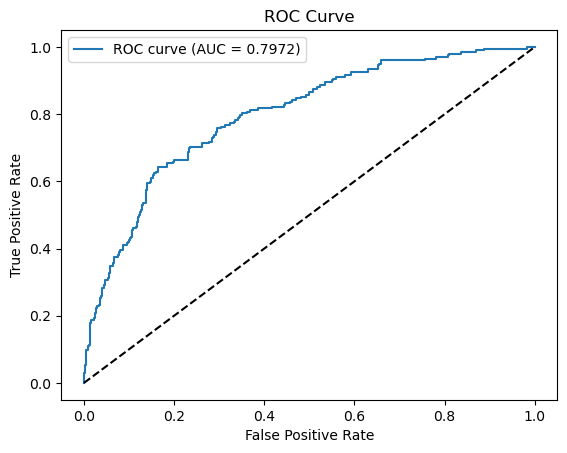

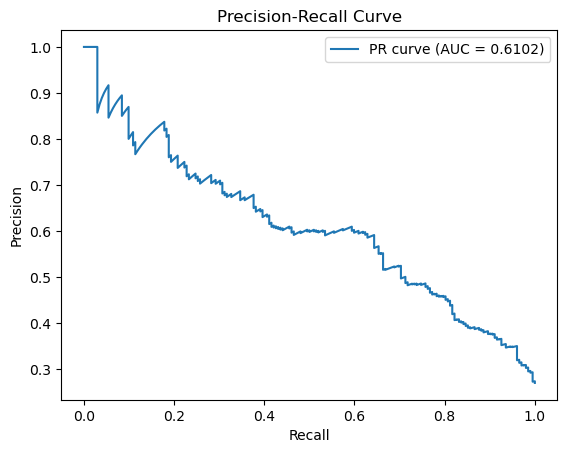

In [28]:
# Convert torch tensors to numpy arrays
y_val_np = y_val.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_val_np, y_pred_np, average='weighted')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_val_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_val_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_val_np, y_prob_np)
pr_auc = average_precision_score(y_val_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()

The accuracy is: 0.772


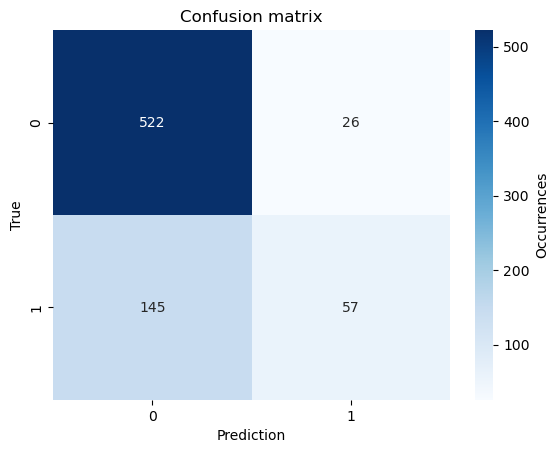

In [29]:
# visualize (final) confusion matrix on test set
y_prob = model(X_test).squeeze() 
y_pred = torch.argmax(y_prob, dim=1)
acc_test = accuracy_fn(y_true=y_test, y_pred=y_pred)
print('The accuracy is:', acc_test)
confusion_matrix(y_test, y_pred)

Compute precision, recall F1 score for the validation set. And plot ROC & AUC

Precision: 0.7568
Recall:    0.7720
F1-score:  0.7356
Class 0 - Precision: 0.7826, Recall: 0.9526, F1-score: 0.8593
Class 1 - Precision: 0.6867, Recall: 0.2822, F1-score: 0.4000


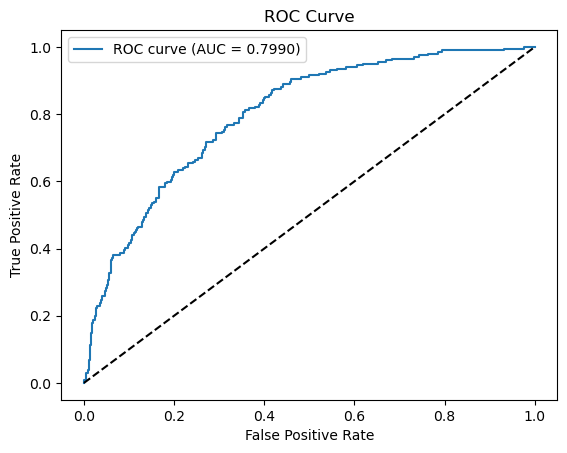

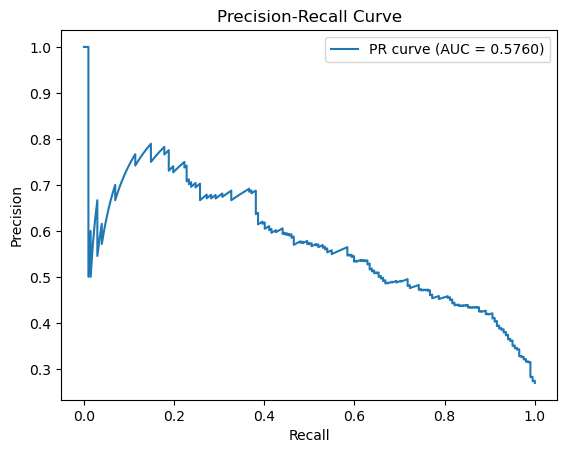

In [30]:
# Convert torch tensors to numpy arrays
y_test_np = y_test.numpy()
y_pred_np = y_pred.numpy()
y_prob_np = y_prob[:, 1].detach().numpy()  # Probability for class 1

# Precision, Recall, F1-score
precision, recall, f1, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average='weighted')
print(f"Precision: {precision:.4f}")
print(f"Recall:    {recall:.4f}")
print(f"F1-score:  {f1:.4f}")
# Precision, Recall, F1-score for both classes
precision_all, recall_all, f1_all, _ = precision_recall_fscore_support(y_test_np, y_pred_np, average=None)
for i, (p, r, f) in enumerate(zip(precision_all, recall_all, f1_all)):
    print(f"Class {i} - Precision: {p:.4f}, Recall: {r:.4f}, F1-score: {f:.4f}")

# ROC Curve & AUC
fpr, tpr, _ = roc_curve(y_test_np, y_prob_np)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, label=f'ROC curve (AUC = {roc_auc:.4f})')
plt.plot([0, 1], [0, 1], 'k--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.show()

# Precision-Recall Curve & AUC
precision_curve, recall_curve, _ = precision_recall_curve(y_test_np, y_prob_np)
pr_auc = average_precision_score(y_test_np, y_prob_np)
plt.figure()
plt.plot(recall_curve, precision_curve, label=f'PR curve (AUC = {pr_auc:.4f})')
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.legend()
plt.show()